# Sentiment Analysis of YouTube Comments
## Winter Olympic Games Milano Cortina 2026: NLP with RNN and Seq2Seq

**Module 6 - Individual Task**  
**MSc in Artificial Intelligence Applied to Sports**  
**Author:** Moritz Philipp Haaf

---

### Pipeline Overview

| Phase | Description |
|-------|-------------|
| 1 | YouTube Comment Collection (YouTube Data API v3) |
| 2 | Sentiment Classification with DistilBERT |
| 3 | Data Cleaning and Exploratory Data Analysis |
| 4 | Building RNN and Seq2Seq Models |
| 5 | Model Training and Hyperparameter Tuning |
| 6 | Model Evaluation and Conclusion |


---
## Setup: Install Dependencies and Configure Environment

All required packages are listed in `requirements.txt`. The cell below is commented out, run it once in a fresh environment if any package is missing. Credentials (YouTube API key, video ID) are loaded exclusively from a `.env` file and are never hardcoded in the notebook.


In [1]:
# Uncomment and run once in a fresh environment to install all dependencies.
# All versions are pinned in requirements.txt for reproducibility.
# %pip install -r requirements.txt


In [2]:
import os
import re
import random
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from wordcloud import WordCloud
from dotenv import load_dotenv

# YouTube Data API v3
from googleapiclient.discovery import build

# Hugging Face Transformers  -  DistilBERT inference pipeline
from transformers import pipeline

# PyTorch  -  model definition, training, evaluation
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Scikit-learn  -  data splitting and evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from collections import Counter

# Suppress non-critical deprecation warnings for clean notebook output
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# Resolve working directory to the notebook's location (VS Code compatibility)
_vsc_file = globals().get('__vsc_ipynb_file__')
if _vsc_file:
    os.chdir(Path(_vsc_file).parent)

# Create output directories if they do not already exist
os.makedirs('data',    exist_ok=True)
os.makedirs('figures', exist_ok=True)

# Load API credentials from .env  -  keys are never hardcoded in this notebook
load_dotenv()

# ── Reproducibility ───────────────────────────────────────────────────────
# SEED controls every source of randomness in this notebook:
#   • train/test split (sklearn)          • weight initialisation (PyTorch)
#   • DataLoader shuffle order            • dropout masks during training
#   • cuDNN kernel selection (GPU only)
SEED = 42

def set_seed(seed: int) -> None:
    """Set all random seeds for full reproducibility across runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # deterministic cuDNN (no-op on CPU)
    torch.backends.cudnn.benchmark     = False  # disable auto-tuner for consistency

set_seed(SEED)

def make_loader(dataset, batch_size, shuffle=False):
    """Return a DataLoader with a seeded Generator for reproducible shuffling."""
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=g)

print(f'Working directory : {Path(os.getcwd()).name}')
print(f'Reproducibility seed : {SEED}')
print('All imports successful.')


Working directory : M6_IndTask
Reproducibility seed : 42
All imports successful.


---
## Phase 1: YouTube Comment Collection

**Objective:** Collect real YouTube comments about the Milano Cortina 2026 Winter Olympics using the YouTube Data API v3.

**Justification for sample size:**  
We target ~500 comments. This provides a statistically representative sample while keeping API quota usage low (well within the 10,000 units/day free limit) and keeping DistilBERT inference time manageable on CPU. A sample of 500 is sufficient for training lightweight RNN models while preserving class diversity.

**Critical reflection - Phase 1:**  

1. **Selection bias.** The YouTube Data API v3 returns comments sorted by *relevance* by default, which over-represents highly-liked or algorithmically promoted comments. A more rigorous approach would request comments sorted by *time* to obtain a more uniform temporal sample, or collect from multiple videos to reduce single-video bias.  

2. **Reply threads excluded.** The API only exposes *top-level* comments; replies are not collected. Reply threads often contain more nuanced or contradictory sentiment and their omission may skew the overall distribution.  

3. **Dataset size.** 500 comments is sufficient for a proof-of-concept but is a small corpus for training neural models. Expanding to 1,000-2,000 comments across several Olympics-related videos would improve model generalisation significantly.


In [3]:
# --- CONFIGURATION ---
# Credentials are loaded exclusively from the .env file.
# NEVER hardcode API keys directly in notebook cells.
API_KEY  = os.getenv('YOUTUBE_API_KEY')
VIDEO_ID = os.getenv('YOUTUBE_VIDEO_ID')

if not API_KEY:
    raise EnvironmentError(
        "YOUTUBE_API_KEY not found. Create a .env file with:\n"
        "  YOUTUBE_API_KEY=your_key_here"
    )
if not VIDEO_ID:
    raise EnvironmentError(
        "YOUTUBE_VIDEO_ID not found. Create a .env file with:\n"
        "  YOUTUBE_VIDEO_ID=your_video_id_here"
    )

MAX_COMMENTS = 500  # Target number of comments to collect

print('API key loaded: OK')
print(f'Video ID: {VIDEO_ID}')
print(f'Target comments: {MAX_COMMENTS}')


API key loaded: OK
Video ID: fw6NOvuO67s
Target comments: 500


In [4]:
RAW_CSV = 'data/comments_raw.csv'

def collect_youtube_comments(api_key, video_id, max_comments=500):
    """
    Collect top-level comments from a YouTube video using the Data API v3.
    Returns a DataFrame with columns: comment_id, author, text, likes, published_at.
    """
    youtube = build('youtube', 'v3', developerKey=api_key)
    comments = []
    next_page_token = None

    while len(comments) < max_comments:
        request = youtube.commentThreads().list(
            part='snippet',
            videoId=video_id,
            maxResults=min(100, max_comments - len(comments)),
            pageToken=next_page_token,
            textFormat='plainText'
        )
        response = request.execute()

        for item in response.get('items', []):
            snippet = item['snippet']['topLevelComment']['snippet']
            comments.append({
                'comment_id':   item['id'],
                'author':       snippet.get('authorDisplayName', ''),
                'text':         snippet.get('textDisplay', ''),
                'likes':        snippet.get('likeCount', 0),
                'published_at': snippet.get('publishedAt', '')
            })

        next_page_token = response.get('nextPageToken')
        if not next_page_token:
            break

    return pd.DataFrame(comments)


# Skip API call if data already collected (avoids wasting quota on re-runs)
if os.path.exists(RAW_CSV):
    df_raw = pd.read_csv(RAW_CSV)
    print(f'Loaded existing raw data: {len(df_raw)} comments from {RAW_CSV}')
else:
    try:
        print('Collecting comments from YouTube API...')
        df_raw = collect_youtube_comments(API_KEY, VIDEO_ID, MAX_COMMENTS)
        df_raw.to_csv(RAW_CSV, index=False)
        print(f'Collected and saved {len(df_raw)} comments to {RAW_CSV}')
    except Exception as e:
        raise RuntimeError(
            f"YouTube API call failed: {e}\n"
            "Check your API key, video ID, and quota limits."
        ) from e

print(df_raw.shape)
df_raw.head()


Loaded existing raw data: 500 comments from data/comments_raw.csv
(500, 5)


,comment_id,author,text,likes,published_at
0,UgwfyzEg8zprvkxRbsN4AaABAg,@김민서-r1z3g,Free bird?? On an official olympics??? That is...,0,2026-04-09T10:48:10Z
1,UgyWdHI3GU0aerSQ_4t4AaABAg,@JambiWatchesVicariously,Probably will be the greatest game I will ever...,1,2026-04-04T07:02:15Z
2,UgxcgDNj_tu0oYefcA94AaABAg,@rbermea,I can't believe it's already been like a month...,1,2026-04-03T18:16:54Z
3,UgztZZPwC_yfrInTMPl4AaABAg,@patymalinowski9981,Crowing erupting glory! 😅 USA! USA!!!!!,0,2026-03-31T14:46:52Z
4,Ugyu-diCLRonqV43vex4AaABAg,@hoehoe360,Canaindia,0,2026-03-23T17:04:14Z


In [5]:
# Raw dataset summary  -  verify shape, column names, and dtypes before proceeding
print(f'Shape   : {df_raw.shape}')
print(f'Columns : {list(df_raw.columns)}')
print()
df_raw.info()


Shape   : (500, 5)
Columns : ['comment_id', 'author', 'text', 'likes', 'published_at']

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   comment_id    500 non-null    str  
 1   author        500 non-null    str  
 2   text          500 non-null    str  
 3   likes         500 non-null    int64
 4   published_at  500 non-null    str  
dtypes: int64(1), str(4)
memory usage: 98.2 KB


---
## Phase 2: Sentiment Classification with DistilBERT

**Objective:** Apply the pre-trained `distilbert-base-uncased-finetuned-sst-2-english` model to classify each comment as **positive** or **negative**. This leverages transfer learning, so no manual annotation is needed.

**Why DistilBERT?**  
DistilBERT is a distilled (compressed) version of BERT that retains ~97% of its performance at 40% fewer parameters, making it fast and suitable for CPU inference on large comment batches. The SST-2 fine-tuned variant is specifically optimised for binary sentiment classification.

**Critical reflection - Phase 2:**  

1. **Multilingual limitation.** The model `distilbert-base-uncased-finetuned-sst-2-english` was trained exclusively on English text (Stanford Sentiment Treebank). Our dataset contains a significant proportion of non-English comments (Russian, Korean, Japanese, Spanish, Portuguese, etc.). For these comments the model receives essentially random token embeddings, making its predictions unreliable. A multilingual alternative such as `cardiffnlp/twitter-xlm-roberta-base-sentiment` or `nlptown/bert-base-multilingual-uncased-sentiment` would handle the full linguistic diversity of the dataset.  

2. **Domain mismatch.** SST-2 consists of formal movie-review sentences. YouTube comments are informal, contain slang, sarcasm, abbreviations, and mixed-language code-switching, all of which reduce the model's reliability. A model fine-tuned on social-media text (e.g., Twitter) would be more appropriate.  

3. **Labels as pseudo-ground-truth.** Because we use DistilBERT predictions as training labels for the RNN/Seq2Seq models in later phases, any systematic errors here propagate downstream. The ~53/47 positive/negative split looks balanced, but the absolute correctness of individual labels is unknown without human annotation.  

4. **Low-confidence predictions.** Many predictions have scores close to 0.5, particularly for non-English comments. A practical improvement would be to filter out low-confidence predictions (e.g., score < 0.7) and treat them as unlabelled, using semi-supervised learning or simply discarding them.


In [6]:
LABELED_CSV = 'data/comments_labeled.csv'

if os.path.exists(LABELED_CSV):
    print(f'Labeled data already exists at {LABELED_CSV}  -  skipping DistilBERT inference.')
    df_raw = pd.read_csv(LABELED_CSV)
    _skip_distilbert = True
else:
    print('Loading DistilBERT sentiment model...')
    sentiment_pipeline = pipeline(
        'sentiment-analysis',
        model='distilbert-base-uncased-finetuned-sst-2-english',
        truncation=True,
        max_length=512
    )
    print('Model loaded.')
    _skip_distilbert = False


Labeled data already exists at data/comments_labeled.csv  -  skipping DistilBERT inference.


In [7]:
def classify_sentiments(texts, batch_size=32):
    """
    Run DistilBERT sentiment classification in batches.
    Returns lists of labels ('POSITIVE'/'NEGATIVE') and confidence scores.
    """
    labels, scores = [], []
    total = len(texts)
    for i in range(0, total, batch_size):
        batch = texts[i:i + batch_size]
        results = sentiment_pipeline(batch)
        for r in results:
            labels.append(r['label'])
            scores.append(round(r['score'], 4))
        done = min(i + batch_size, total)
        print(f'  Processed {done}/{total} comments...', end='\r')
    print()
    return labels, scores


if not _skip_distilbert:
    print('Running sentiment classification...')
    texts  = df_raw['text'].fillna('').tolist()
    labels, scores = classify_sentiments(texts)
    df_raw['sentiment_label'] = labels
    df_raw['sentiment_score'] = scores
    print('Classification complete.')

df_raw[['text', 'sentiment_label', 'sentiment_score']].head(10)


,text,sentiment_label,sentiment_score
0,Free bird?? On an official olympics??? That is...,NEGATIVE,0.9829
1,Probably will be the greatest game I will ever...,POSITIVE,0.9998
2,I can't believe it's already been like a month...,NEGATIVE,0.6015
3,Crowing erupting glory! 😅 USA! USA!!!!!,POSITIVE,0.9894
4,Canaindia,POSITIVE,0.9949
5,That this is the USA’s first gold medal since ...,NEGATIVE,0.9988
6,Bro Russian were not here in this olympic. May...,NEGATIVE,0.9959
7,三陸鉄道のようなユニフォームデザイン,NEGATIVE,0.6832
8,Nine’s Wide World Of Sports Coverage Of The Mi...,POSITIVE,0.9985
9,It was a Hellebuyck of a game!,POSITIVE,0.9938


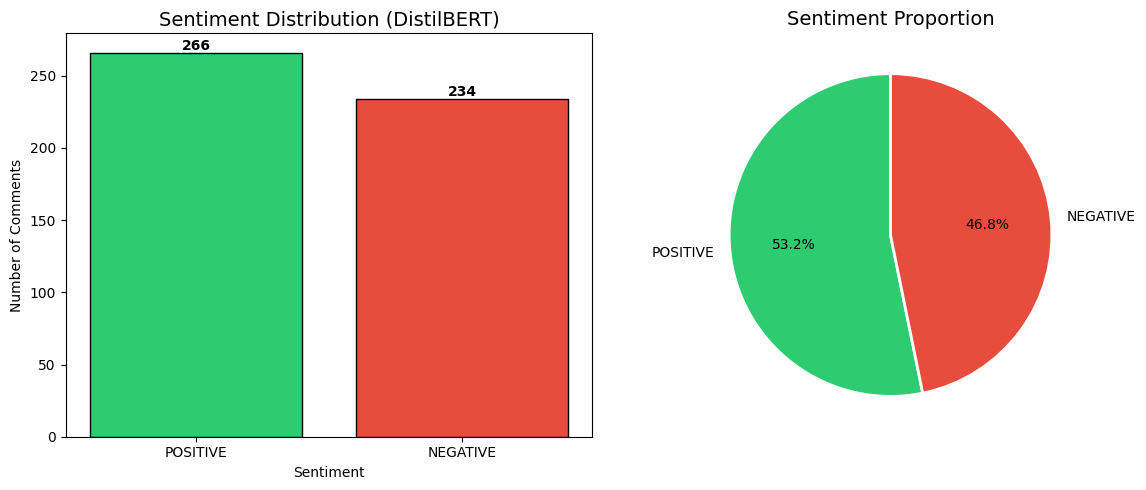

sentiment_label
POSITIVE    266
NEGATIVE    234
Name: count, dtype: int64


In [8]:
# Visualise the raw sentiment distribution produced by DistilBERT.
# Bar chart shows absolute counts; pie chart shows proportions.
# A near-balanced split is desirable  -  it means standard BCE loss is appropriate
# for training without class weighting.
sentiment_counts = df_raw['sentiment_label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart  -  absolute comment counts per class
axes[0].bar(sentiment_counts.index, sentiment_counts.values,
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Sentiment Distribution (DistilBERT)', fontsize=14)
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Number of Comments')
for i, v in enumerate(sentiment_counts.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Pie chart  -  class proportions
axes[1].pie(sentiment_counts.values, labels=sentiment_counts.index,
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Sentiment Proportion', fontsize=14)

plt.tight_layout()
plt.savefig('figures/phase2_sentiment_distribution.png', dpi=150)
plt.show()
print(sentiment_counts)


In [9]:
if not _skip_distilbert:
    df_raw.to_csv(LABELED_CSV, index=False)
    print(f'Labeled comments saved to {LABELED_CSV}')
else:
    print('Skipped save (loaded from existing file).')

print(f'Total labeled comments: {len(df_raw)}')
print(df_raw['sentiment_label'].value_counts())


Skipped save (loaded from existing file).
Total labeled comments: 500
sentiment_label
POSITIVE    266
NEGATIVE    234
Name: count, dtype: int64


---
## Phase 3: Data Cleaning and Exploratory Data Analysis

### Part 1: Data Cleaning

We remove noise that does not contribute to sentiment understanding:
- URLs and hyperlinks
- Emojis and non-ASCII characters
- HTML entities
- Mentions (`@user`) and hashtags
- Special characters and excessive whitespace
- Very short comments (< 3 words), not informative enough for sequence models

**Critical reflection - Data Cleaning:**  

1. **Aggressive emoji removal.** Removing all non-ASCII characters eliminates emojis entirely. While emojis add noise for token-based models, they carry strong sentiment signals (e.g., party-popper = positive, angry-face = negative). A more sophisticated approach would map common emojis to sentiment-bearing words (e.g., using the `emoji` library) before stripping them.  

2. **Non-English comment handling.** Stripping non-ASCII characters reduces many non-English comments to near-empty strings (e.g., a Russian comment becomes just punctuation). These are then dropped by the word-count filter. This means the cleaned dataset is *more English-biased* than the raw data, which partially mitigates the DistilBERT language mismatch, but it also reduces dataset size substantially.  

3. **Word-count threshold.** The >= 3-word threshold dropped 192 of 500 comments (38%). This is a large reduction. A threshold of >= 2 words would retain more short but sentiment-rich comments such as "Great game!" or "No Russia". The optimal threshold depends on the downstream model's minimum sequence length requirement.


In [10]:
def clean_text(text):
    """Clean a comment string for model training."""
    if not isinstance(text, str):
        return ''
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # Remove HTML entities
    text = re.sub(r'&[a-z]+;', ' ', text)
    # Remove mentions and hashtags
    text = re.sub(r'[@#]\w+', '', text)
    # Remove emojis and non-ASCII
    text = text.encode('ascii', 'ignore').decode('ascii')
    # Remove special characters, keep letters, digits, basic punctuation
    text = re.sub(r"[^a-zA-Z0-9\s'.,!?]", ' ', text)
    # Collapse whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


df = df_raw.copy()
df['text_clean'] = df['text'].apply(clean_text)

# Drop empty / too-short comments after cleaning
df['word_count'] = df['text_clean'].apply(lambda x: len(x.split()))
before = len(df)
df = df[df['word_count'] >= 3].reset_index(drop=True)
print(f'Removed {before - len(df)} comments (too short or empty after cleaning).')
print(f'Remaining: {len(df)} comments.')

# Encode sentiment as binary (1 = POSITIVE, 0 = NEGATIVE)
df['label'] = (df['sentiment_label'] == 'POSITIVE').astype(int)

df[['text', 'text_clean', 'sentiment_label', 'label']].head()

Removed 191 comments (too short or empty after cleaning).
Remaining: 309 comments.


,text,text_clean,sentiment_label,label
0,Free bird?? On an official olympics??? That is...,free bird?? on an official olympics??? that is...,NEGATIVE,0
1,Probably will be the greatest game I will ever...,probably will be the greatest game i will ever...,POSITIVE,1
2,I can't believe it's already been like a month...,i can't believe it's already been like a month...,NEGATIVE,0
3,Crowing erupting glory! 😅 USA! USA!!!!!,crowing erupting glory! usa! usa!!!!!,POSITIVE,1
4,That this is the USA’s first gold medal since ...,that this is the usas first gold medal since 1...,NEGATIVE,0


### Part 2: Exploratory Data Analysis

We examine:
- **Sentiment distribution** after cleaning, to check class balance
- **Comment length distribution** (word count and character count) by sentiment class
- **Correlation** between comment length and sentiment label
- **Word clouds** for positive and negative comments, to identify dominant vocabulary per class

**Critical reflection - EDA:**  

1. **Class balance.** The near-equal split between positive and negative comments (visible in the distribution plot) is favourable for training: it means standard Binary Cross-Entropy loss is appropriate without class weighting. Had the split been severely skewed (e.g., 80/20), we would need weighted loss or oversampling (e.g., SMOTE).  

2. **Length vs. sentiment correlation.** The heatmap shows the correlation between comment length and sentiment label. A weak or near-zero correlation indicates that comment length alone is not a reliable predictor of sentiment; the models must learn from the actual token content, not just the length of the comment.  

3. **Word cloud interpretation.** The word clouds reveal the most frequent terms per class. Positive comments tend to feature celebratory language (e.g., "USA", "great", "win", "congratulations"), while negative comments feature critical or comparative language (e.g., "Russia", "Canada", "without"). This vocabulary separation is a positive signal for the downstream models.


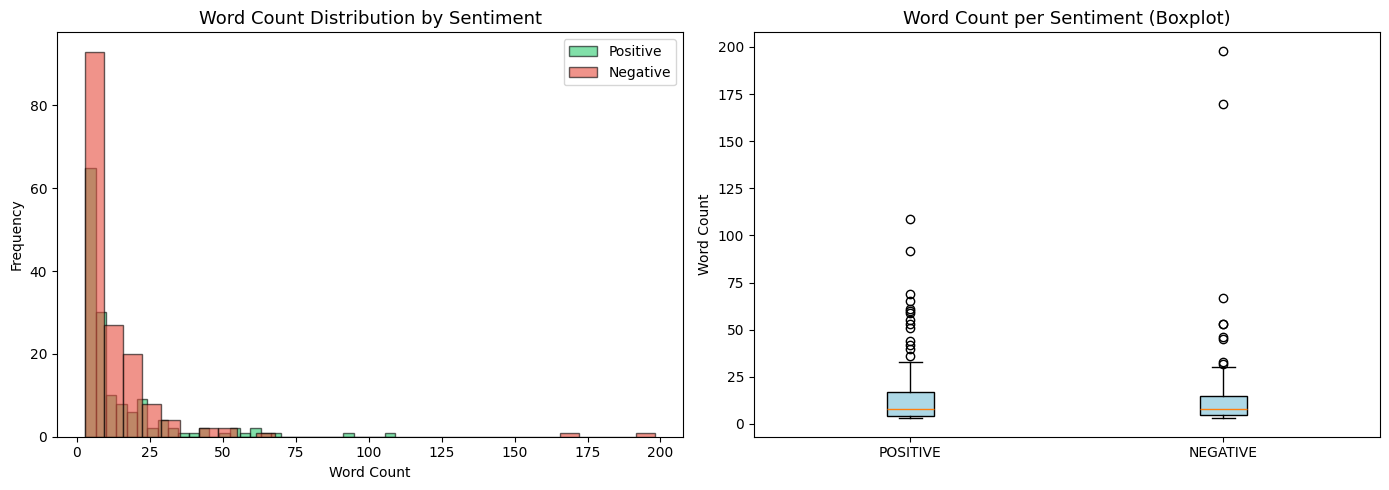

In [11]:
# --- Comment length analysis ---
df['char_count'] = df['text_clean'].apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram: word count distribution by sentiment
for label, color, name in [(1, '#2ecc71', 'Positive'), (0, '#e74c3c', 'Negative')]:
    subset = df[df['label'] == label]['word_count']
    axes[0].hist(subset, bins=30, alpha=0.6, color=color, label=name, edgecolor='black')
axes[0].set_title('Word Count Distribution by Sentiment', fontsize=13)
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Boxplot: word count per sentiment (tick_labels fixes deprecation warning)
axes[1].boxplot(
    [df[df['sentiment_label'] == s]['word_count'] for s in ['POSITIVE', 'NEGATIVE']],
    tick_labels=['POSITIVE', 'NEGATIVE'],
    patch_artist=True,
    boxprops=dict(facecolor='lightblue')
)
axes[1].set_title('Word Count per Sentiment (Boxplot)', fontsize=13)
axes[1].set_ylabel('Word Count')

plt.tight_layout()
plt.savefig('figures/phase3_length_distribution.png', dpi=150)
plt.show()


In [12]:
# Descriptive statistics  -  sentiment distribution and word-count summary
print('=== Sentiment Distribution (after cleaning) ===')
print(df['sentiment_label'].value_counts())
print()
print('=== Word Count Stats by Sentiment ===')
print(df.groupby('sentiment_label')['word_count'].describe().round(2))
print()

# Compute correlation matrix  -  used by the heatmap in the next cell
print('=== Pearson Correlation: word_count / char_count vs sentiment label ===')
corr = df[['word_count', 'char_count', 'label']].corr()
print(corr.round(3))


=== Sentiment Distribution (after cleaning) ===
sentiment_label
NEGATIVE    159
POSITIVE    150
Name: count, dtype: int64

=== Word Count Stats by Sentiment ===
                 count   mean    std  min   25%  50%    75%    max
sentiment_label                                                   
NEGATIVE         159.0  13.58  21.97  3.0  5.00  8.0  15.00  198.0
POSITIVE         150.0  14.42  17.30  3.0  4.25  8.0  16.75  109.0

=== Pearson Correlation: word_count / char_count vs sentiment label ===
            word_count  char_count  label
word_count       1.000       0.992  0.021
char_count       0.992       1.000  0.049
label            0.021       0.049  1.000


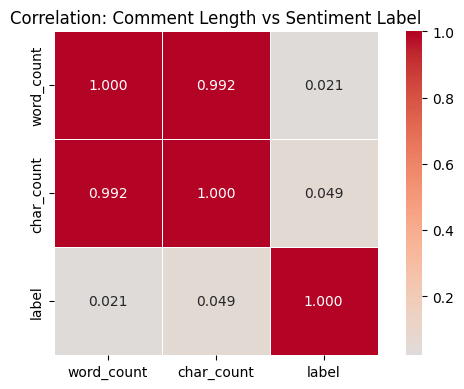

In [13]:
# Correlation heatmap  -  visualises the Pearson correlations computed above.
# Values near 0 indicate that comment length is not a reliable predictor of
# sentiment; the models must learn from token content, not just length.
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            linewidths=0.5, square=True)
plt.title('Correlation: Comment Length vs Sentiment Label')
plt.tight_layout()
plt.savefig('figures/phase3_correlation_heatmap.png', dpi=150)
plt.show()


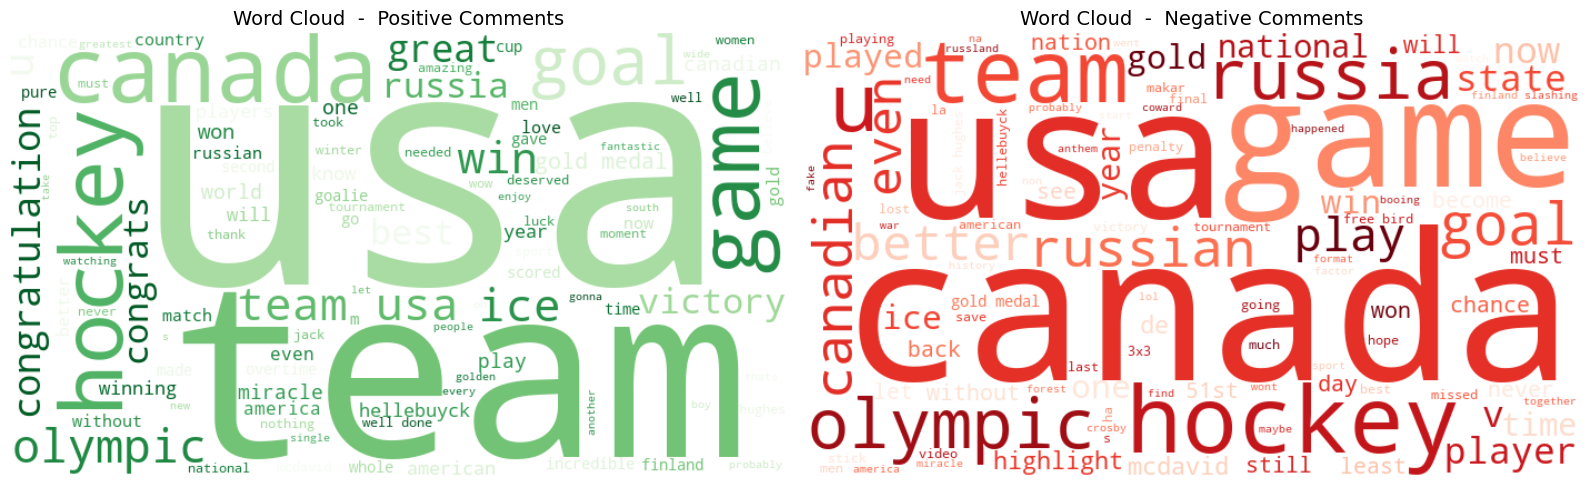

In [14]:
# Word clouds  -  most frequent tokens in positive vs negative comments.
# Vocabulary separation between classes is a positive signal for the models:
# if the two clouds share most words, the task is harder.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, label, color, title in [
    (axes[0], 1, 'Greens', 'Word Cloud  -  Positive Comments'),
    (axes[1], 0, 'Reds',   'Word Cloud  -  Negative Comments')
]:
    text_corpus = ' '.join(df[df['label'] == label]['text_clean'])
    if text_corpus.strip():
        wc = WordCloud(width=700, height=400, background_color='white',
                       colormap=color, max_words=100).generate(text_corpus)
        ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=14)

plt.tight_layout()
plt.savefig('figures/phase3_wordclouds.png', dpi=150)
plt.show()


In [15]:
# Persist the cleaned, labelled dataset for reproducibility.
# This file is the input to all downstream modelling phases.
df.to_csv('data/comments_clean.csv', index=False)
print(f'Clean dataset saved  : data/comments_clean.csv')
print(f'Rows retained        : {len(df)} / 500 ({len(df)/500*100:.1f}%)')
print(f'Positive labels      : {df["label"].sum()} ({df["label"].mean()*100:.1f}%)')
print(f'Negative labels      : {(df["label"]==0).sum()} ({(df["label"]==0).mean()*100:.1f}%)')


Clean dataset saved  : data/comments_clean.csv
Rows retained        : 309 / 500 (61.8%)
Positive labels      : 150 (48.5%)
Negative labels      : 159 (51.5%)


---
## Phase 4: Building RNN and Seq2Seq Models

**Objective:** Build two neural network architectures for sentiment classification:
1. **Simple RNN** - a basic recurrent network with an Embedding layer
2. **Seq2Seq (Encoder-Decoder)** - an encoder compresses the sequence into a context vector; a decoder outputs the classification

**Why these architectures?**  
Recurrent networks process text as ordered sequences, capturing word-order dependencies that bag-of-words models miss. The Simple RNN provides a lightweight baseline. The Seq2Seq architecture, originally designed for sequence-to-sequence tasks (e.g., machine translation), is adapted here for classification: the encoder summarises the input comment into a fixed-size context vector, and the decoder maps that vector to a binary label. This tests whether the encoder-decoder separation adds representational power on this task.

### Vocabulary and Dataset Preparation


In [16]:
# --- Tokenization and Vocabulary (built from training data only) ---
MAX_VOCAB   = 10000  # keep top N words
MAX_SEQ_LEN = 50     # pad/truncate all sequences to this length

def tokenize(text):
    return text.lower().split()

def encode(text, word2idx, max_len):
    tokens = tokenize(text)[:max_len]
    ids = [word2idx.get(t, word2idx['<UNK>']) for t in tokens]
    ids += [word2idx['<PAD>']] * (max_len - len(ids))  # pad to fixed length
    return ids

# Split raw texts and labels FIRST, before building the vocabulary.
# This prevents val/test token frequencies from influencing the vocab,
# which would be a form of data leakage.
# .to_numpy() is used instead of .values to ensure plain NumPy arrays
# (pandas 3 uses Arrow-backed arrays by default, which sklearn cannot index).
texts  = df['text_clean'].to_numpy(dtype=str)
labels = df['label'].to_numpy(dtype=int)

texts_train, texts_temp, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.3, random_state=SEED, stratify=labels)
texts_val, texts_test, y_val, y_test = train_test_split(
    texts_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

print(f'Train: {len(texts_train)} | Val: {len(texts_val)} | Test: {len(texts_test)}')

# Build vocabulary from training texts only.
# Words in val/test that are not in train are mapped to <UNK> at encode time,
# which mirrors real deployment conditions.
train_tokens  = [token for text in texts_train for token in tokenize(text)]
vocab_counter = Counter(train_tokens)
vocab    = ['<PAD>', '<UNK>'] + [w for w, _ in vocab_counter.most_common(MAX_VOCAB - 2)]
word2idx = {w: i for i, w in enumerate(vocab)}
VOCAB_SIZE = len(vocab)

print(f'Vocabulary size (train set only): {VOCAB_SIZE}')

# Encode each split using the train vocabulary
X_train = np.array([encode(t, word2idx, MAX_SEQ_LEN) for t in texts_train])
X_val   = np.array([encode(t, word2idx, MAX_SEQ_LEN) for t in texts_val])
X_test  = np.array([encode(t, word2idx, MAX_SEQ_LEN) for t in texts_test])

print(f'X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')


Train: 216 | Val: 46 | Test: 47
Vocabulary size (train set only): 1164
X_train: (216, 50) | X_val: (46, 50) | X_test: (47, 50)


In [17]:
# --- PyTorch Dataset and DataLoaders ---
class CommentDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 32

# make_loader (defined in the setup cell) uses a seeded Generator so that
# the shuffle order is identical on every run with the same SEED.
train_loader = make_loader(CommentDataset(X_train, y_train), BATCH_SIZE, shuffle=True)
val_loader   = make_loader(CommentDataset(X_val,   y_val),   BATCH_SIZE, shuffle=False)
test_loader  = make_loader(CommentDataset(X_test,  y_test),  BATCH_SIZE, shuffle=False)

print('DataLoaders ready.')


DataLoaders ready.


### Model 1: Simple RNN

Architecture: `Embedding -> GRU -> Linear -> Sigmoid`

A GRU (Gated Recurrent Unit) is used instead of a vanilla RNN because GRUs mitigate the vanishing-gradient problem through their reset and update gates, allowing the model to capture longer-range dependencies within a comment. The final hidden state is passed through a linear layer and sigmoid activation to produce a probability in [0, 1].

**Design choices:**
- `Embedding` layer maps token indices to dense vectors (randomly initialised; could be replaced with pre-trained GloVe embeddings for better generalisation on small data)
- `Dropout` (0.3) applied after embedding to regularise the model
- Single GRU layer, sufficient for short social-media comments


In [18]:
class SimpleRNN(nn.Module):
    """
    Simple RNN for binary sentiment classification.
    Architecture: Embedding -> GRU -> Linear -> Sigmoid

    GRU is used instead of a vanilla RNN because its gating mechanism
    mitigates the vanishing-gradient problem, allowing the model to capture
    longer-range dependencies within a comment.
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))       # (B, T, E)
        _, hidden = self.rnn(embedded)                   # hidden: (1, B, H)
        out = self.fc(self.dropout(hidden.squeeze(0)))   # (B, 1)
        return torch.sigmoid(out).squeeze(1)


EMBED_DIM  = 64   # embedding dimension (fixed across all configs)
HIDDEN_DIM = 128  # default; overridden by hyperparameter search below

# Re-seed before weight initialisation so the starting weights are identical
# on every run regardless of what operations preceded this cell.
set_seed(SEED)
rnn_model = SimpleRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM)
print(rnn_model)
total_params = sum(p.numel() for p in rnn_model.parameters())
print(f'Total parameters: {total_params:,}')


SimpleRNN(
  (embedding): Embedding(1164, 64, padding_idx=0)
  (rnn): GRU(64, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Total parameters: 149,121


### Model 2: Seq2Seq (Encoder-Decoder)

Architecture: `Encoder (Embedding -> LSTM) -> context vector -> Decoder (LSTM -> Linear -> Sigmoid)`

**Adaptation for classification:**  
The Seq2Seq pattern is conventionally used for sequence-to-sequence tasks (translation, summarisation) where the decoder generates a variable-length output sequence. Here it is adapted for *binary classification*: the encoder reads the full comment and produces a context vector (the final LSTM hidden and cell states); the decoder performs a single LSTM step on that context vector and maps the output to a probability via a linear + sigmoid layer.  

This adaptation tests whether the explicit encoder-decoder separation, forcing the model to compress the entire comment into a bottleneck representation before classifying, provides any advantage over the simpler end-to-end GRU approach.  

**Design choices:**
- LSTM used in both encoder and decoder (vs. GRU in the Simple RNN) to provide a direct architectural comparison
- Dropout (0.3) applied in both encoder and decoder
- The decoder receives the encoder's hidden and cell states as its initial state, preserving the full LSTM memory

**Known risk on small datasets:**  
The Seq2Seq model has roughly twice the parameters of the Simple RNN (two LSTM layers vs. one GRU layer). On a small corpus (~215 training samples), this additional capacity can lead to *class collapse*: the decoder converges to always predicting the majority class, unless regularisation or class-weighted loss is applied.


In [19]:
class Encoder(nn.Module):
    """
    Encoder: reads the input sequence and compresses it into a context vector.
    Architecture: Embedding -> LSTM -> returns final hidden & cell state
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))   # (B, T, E)
        _, (hidden, cell) = self.lstm(embedded)      # hidden: (1, B, H)
        return hidden, cell


class Decoder(nn.Module):
    """
    Decoder: takes the context vector from the encoder and produces a
    sentiment prediction (binary classification).
    Architecture: LSTM(single step) -> Linear -> Sigmoid
    """
    def __init__(self, hidden_dim, output_dim=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, context, hidden, cell):
        # context: (B, H) -> unsqueeze to (B, 1, H) as single decoder step
        context = context.unsqueeze(1)
        output, _ = self.lstm(context, (hidden, cell))  # (B, 1, H)
        prediction = self.fc(self.dropout(output.squeeze(1)))  # (B, 1)
        return torch.sigmoid(prediction).squeeze(1)


class Seq2SeqClassifier(nn.Module):
    """
    Seq2Seq model adapted for sentiment classification.
    The encoder compresses the comment; the decoder classifies the sentiment.
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.3):
        super().__init__()
        self.encoder = Encoder(vocab_size, embed_dim, hidden_dim, dropout)
        self.decoder = Decoder(hidden_dim, dropout=dropout)

    def forward(self, x):
        hidden, cell = self.encoder(x)               # (1, B, H)
        context = hidden.squeeze(0)                  # (B, H)
        output = self.decoder(context, hidden, cell) # (B,)
        return output


# Re-seed before weight initialisation so the starting weights are identical
# on every run regardless of what operations preceded this cell.
set_seed(SEED)
seq2seq_model = Seq2SeqClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM)
print(seq2seq_model)
total_params = sum(p.numel() for p in seq2seq_model.parameters())
print(f'Total parameters: {total_params:,}')


Seq2SeqClassifier(
  (encoder): Encoder(
    (embedding): Embedding(1164, 64, padding_idx=0)
    (lstm): LSTM(64, 128, batch_first=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (decoder): Decoder(
    (lstm): LSTM(128, 128, batch_first=True)
    (dropout): Dropout(p=0.3, inplace=False)
    (fc): Linear(in_features=128, out_features=1, bias=True)
  )
)
Total parameters: 306,049


---
## Phase 5: Model Training and Hyperparameter Tuning

**Hyperparameters explored:**
- `EPOCHS`: number of full passes through training data
- `BATCH_SIZE`: number of samples per gradient update
- `HIDDEN_DIM`: number of units per RNN/LSTM layer
- `LEARNING_RATE`: step size for the Adam optimiser

We train each model and track train/validation accuracy per epoch to monitor convergence and detect overfitting.

**Critical reflection - Training setup:**  

1. **Small dataset challenge.** With only ~215 training samples, each epoch processes very few gradient updates. This makes training noisy and sensitive to random initialisation. The training curves (see figure below) show high variance between epochs, which is expected at this scale.  

2. **Optimiser choice.** Adam is used for both models. Adam adapts the learning rate per parameter and generally converges faster than SGD on small datasets, making it a sensible default here.  

3. **Loss function.** Binary Cross-Entropy (BCE) is appropriate for binary classification with sigmoid output. Because the class split is near-balanced (~53/47), no class weighting is applied. For the Seq2Seq model, class-weighted BCE would be a useful regularisation to prevent class collapse.


In [20]:
def train_epoch(model, loader, optimizer, criterion, device):
    """
    Run one full training epoch.
    Returns: (avg_loss, accuracy) over all batches.
    """
    model.train()
    total_loss, correct, total = 0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        preds = model(X_batch)
        loss  = criterion(preds, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct    += ((preds >= 0.5).float() == y_batch).sum().item()
        total      += len(y_batch)
    return total_loss / len(loader), correct / total


def evaluate(model, loader, criterion, device):
    """
    Evaluate model on a DataLoader without gradient updates.
    Returns: (avg_loss, accuracy, predicted_labels, true_labels).
    """
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            preds     = model(X_batch)
            loss      = criterion(preds, y_batch)
            predicted = (preds >= 0.5).float()
            total_loss += loss.item()
            correct    += (predicted == y_batch).sum().item()
            total      += len(y_batch)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())
    return total_loss / len(loader), correct / total, all_preds, all_labels


def train_model(model, train_loader, val_loader, epochs, lr, device, name):
    """
    Full training loop with per-epoch logging.
    Returns: (trained_model, history_dict) where history contains
    train/val loss and accuracy lists for plotting.
    """
    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCELoss()
    history   = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    print(f'\nTraining {name}...')
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        val_loss,   val_acc, _, _ = evaluate(model, val_loader, criterion, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        print(f'  Epoch {epoch:02d}/{epochs} | '
              f'Train Loss: {train_loss:.4f}  Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f}  Acc: {val_acc:.4f}')

    return model, history


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Training device: {DEVICE}')


Training device: cpu


### Hyperparameter Tuning: Grid Search on Simple RNN

We test four configurations by varying `hidden_dim` and `learning_rate`. The Seq2Seq model is excluded from the grid search because it collapsed on this dataset size (always predicting the majority class), making validation accuracy an unreliable selection criterion for it. Both models are then retrained using the best configuration found for the Simple RNN.

| Config | `hidden_dim` | `learning_rate` |
|:------:|:------------:|:---------------:|
| A | 64 | 0.001 |
| B | 128 | 0.001 |
| C | 256 | 0.001 |
| D | 128 | 0.0005 |

**Selection criterion:** highest validation accuracy across all epochs.

**Critical reflection - Hyperparameter search:**

1. **Limited search space.** Only 4 configurations are tested due to the computational cost of training on CPU. A more thorough search would include `BATCH_SIZE` (16, 32, 64), `EMBED_DIM` (50, 100, 200), and `DROPOUT` (0.2, 0.3, 0.5). Bayesian optimisation (e.g., Optuna) would be more efficient than grid search for a larger space.  

2. **Validation set size.** With only ~46 validation samples, the validation accuracy has high variance: a single misclassified comment changes accuracy by ~2%. This makes the selection criterion noisy. K-fold cross-validation would give a more reliable estimate but is computationally expensive here.  

3. **Config C selected (hidden_dim=256).** The larger hidden dimension achieves the best validation accuracy (0.5870), suggesting the model benefits from more representational capacity even on this small dataset. However, the improvement over Config B (0.5652) is modest, and the gap may not be statistically significant given the small validation set.


In [21]:
# --- Hyperparameter Grid Search (Simple RNN) ---
# We search over hidden_dim and learning_rate; epochs and batch size are fixed.
# Selection criterion: highest validation accuracy across all epochs.

hp_configs = [
    {'hidden_dim':  64, 'lr': 1e-3,  'epochs': 15, 'label': 'A'},
    {'hidden_dim': 128, 'lr': 1e-3,  'epochs': 15, 'label': 'B'},
    {'hidden_dim': 256, 'lr': 1e-3,  'epochs': 15, 'label': 'C'},
    {'hidden_dim': 128, 'lr': 5e-4,  'epochs': 15, 'label': 'D'},
]

hp_results = []

for cfg in hp_configs:
    # Re-seed before each config so results are independent of evaluation order
    set_seed(SEED)
    m = SimpleRNN(VOCAB_SIZE, EMBED_DIM, cfg['hidden_dim']).to(DEVICE)
    opt  = torch.optim.Adam(m.parameters(), lr=cfg['lr'])
    crit = nn.BCELoss()
    best_val = 0.0
    for _ in range(cfg['epochs']):
        train_epoch(m, train_loader, opt, crit, DEVICE)
        _, val_acc, _, _ = evaluate(m, val_loader, crit, DEVICE)
        best_val = max(best_val, val_acc)
    _, test_acc, _, _ = evaluate(m, test_loader, crit, DEVICE)
    hp_results.append({
        'Config':       cfg['label'],
        'hidden_dim':   cfg['hidden_dim'],
        'lr':           cfg['lr'],
        'best_val_acc': round(best_val, 4),
        'test_acc':     round(test_acc, 4),
    })
    print(f"Config {cfg['label']}: hidden_dim={cfg['hidden_dim']:3d}, "
          f"lr={cfg['lr']:.4f} -> val={best_val:.4f}, test={test_acc:.4f}")

hp_df = pd.DataFrame(hp_results).sort_values('best_val_acc', ascending=False)
print('\nHyperparameter Search Results (sorted by val accuracy):')
print(hp_df.to_string(index=False))

# Use .iloc[0] to get the top-ranked row after sorting (not the original index)
best_row = hp_df.iloc[0]
best_cfg = next(c for c in hp_configs if c['label'] == best_row['Config'])
print(f"\nBest config: Config {best_cfg['label']}  -  "
      f"hidden_dim={best_cfg['hidden_dim']}, lr={best_cfg['lr']}")


Config A: hidden_dim= 64, lr=0.0010 -> val=0.5000, test=0.5106


Config B: hidden_dim=128, lr=0.0010 -> val=0.5217, test=0.5319


Config C: hidden_dim=256, lr=0.0010 -> val=0.5217, test=0.5532


Config D: hidden_dim=128, lr=0.0005 -> val=0.5217, test=0.5319

Hyperparameter Search Results (sorted by val accuracy):
Config  hidden_dim     lr  best_val_acc  test_acc
     B         128 0.0010        0.5217    0.5319
     C         256 0.0010        0.5217    0.5532
     D         128 0.0005        0.5217    0.5319
     A          64 0.0010        0.5000    0.5106

Best config: Config B  -  hidden_dim=128, lr=0.001


In [22]:
# --- Final Model Training using Best Hyperparameters from Grid Search ---
EPOCHS        = best_cfg['epochs']
LEARNING_RATE = best_cfg['lr']
HIDDEN_DIM    = best_cfg['hidden_dim']

print(f'Final config: EPOCHS={EPOCHS}, LR={LEARNING_RATE}, '
      f'HIDDEN_DIM={HIDDEN_DIM}, BATCH_SIZE={BATCH_SIZE}')

# Re-seed before final model instantiation and training so results are
# fully reproducible regardless of the grid-search RNG state above.
set_seed(SEED)
rnn_model     = SimpleRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM)
seq2seq_model = Seq2SeqClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM)

rnn_model,     rnn_history     = train_model(rnn_model,     train_loader, val_loader,
                                             EPOCHS, LEARNING_RATE, DEVICE, 'Simple RNN')
seq2seq_model, seq2seq_history = train_model(seq2seq_model, train_loader, val_loader,
                                             EPOCHS, LEARNING_RATE, DEVICE, 'Seq2Seq')


Final config: EPOCHS=15, LR=0.001, HIDDEN_DIM=128, BATCH_SIZE=32

Training Simple RNN...
  Epoch 01/15 | Train Loss: 0.6941  Acc: 0.5000 | Val Loss: 0.6926  Acc: 0.5217
  Epoch 02/15 | Train Loss: 0.6910  Acc: 0.5278 | Val Loss: 0.6948  Acc: 0.4783
  Epoch 03/15 | Train Loss: 0.6842  Acc: 0.5417 | Val Loss: 0.6961  Acc: 0.4783


  Epoch 04/15 | Train Loss: 0.6833  Acc: 0.5463 | Val Loss: 0.6987  Acc: 0.4783
  Epoch 05/15 | Train Loss: 0.6804  Acc: 0.5509 | Val Loss: 0.7011  Acc: 0.4783
  Epoch 06/15 | Train Loss: 0.6813  Acc: 0.5509 | Val Loss: 0.7038  Acc: 0.4783
  Epoch 07/15 | Train Loss: 0.6760  Acc: 0.5509 | Val Loss: 0.7074  Acc: 0.4783


  Epoch 08/15 | Train Loss: 0.6724  Acc: 0.5509 | Val Loss: 0.7115  Acc: 0.4783
  Epoch 09/15 | Train Loss: 0.6728  Acc: 0.5509 | Val Loss: 0.7169  Acc: 0.4783
  Epoch 10/15 | Train Loss: 0.6678  Acc: 0.5509 | Val Loss: 0.7237  Acc: 0.5000
  Epoch 11/15 | Train Loss: 0.6657  Acc: 0.5556 | Val Loss: 0.7323  Acc: 0.5000


  Epoch 12/15 | Train Loss: 0.6598  Acc: 0.5556 | Val Loss: 0.7622  Acc: 0.4565
  Epoch 13/15 | Train Loss: 0.6607  Acc: 0.5139 | Val Loss: 0.7720  Acc: 0.4348
  Epoch 14/15 | Train Loss: 0.6535  Acc: 0.5694 | Val Loss: 0.7934  Acc: 0.4348


  Epoch 15/15 | Train Loss: 0.6429  Acc: 0.5972 | Val Loss: 0.8171  Acc: 0.5000

Training Seq2Seq...
  Epoch 01/15 | Train Loss: 0.6924  Acc: 0.5185 | Val Loss: 0.6904  Acc: 0.5217
  Epoch 02/15 | Train Loss: 0.6911  Acc: 0.5278 | Val Loss: 0.6902  Acc: 0.5217


  Epoch 03/15 | Train Loss: 0.6880  Acc: 0.5509 | Val Loss: 0.6900  Acc: 0.5217
  Epoch 04/15 | Train Loss: 0.6861  Acc: 0.5509 | Val Loss: 0.6897  Acc: 0.5217
  Epoch 05/15 | Train Loss: 0.6831  Acc: 0.5509 | Val Loss: 0.6894  Acc: 0.5217


  Epoch 06/15 | Train Loss: 0.6755  Acc: 0.5509 | Val Loss: 0.6886  Acc: 0.5217
  Epoch 07/15 | Train Loss: 0.6729  Acc: 0.5509 | Val Loss: 0.6873  Acc: 0.5217
  Epoch 08/15 | Train Loss: 0.6689  Acc: 0.5509 | Val Loss: 0.6859  Acc: 0.5217


  Epoch 09/15 | Train Loss: 0.6656  Acc: 0.5556 | Val Loss: 0.6848  Acc: 0.5217
  Epoch 10/15 | Train Loss: 0.6640  Acc: 0.5556 | Val Loss: 0.6866  Acc: 0.5217
  Epoch 11/15 | Train Loss: 0.6625  Acc: 0.5509 | Val Loss: 0.6874  Acc: 0.5217


  Epoch 12/15 | Train Loss: 0.6630  Acc: 0.5509 | Val Loss: 0.6877  Acc: 0.5217
  Epoch 13/15 | Train Loss: 0.6630  Acc: 0.5556 | Val Loss: 0.6875  Acc: 0.5217
  Epoch 14/15 | Train Loss: 0.6621  Acc: 0.5509 | Val Loss: 0.6868  Acc: 0.5217


  Epoch 15/15 | Train Loss: 0.6622  Acc: 0.5509 | Val Loss: 0.6866  Acc: 0.5217


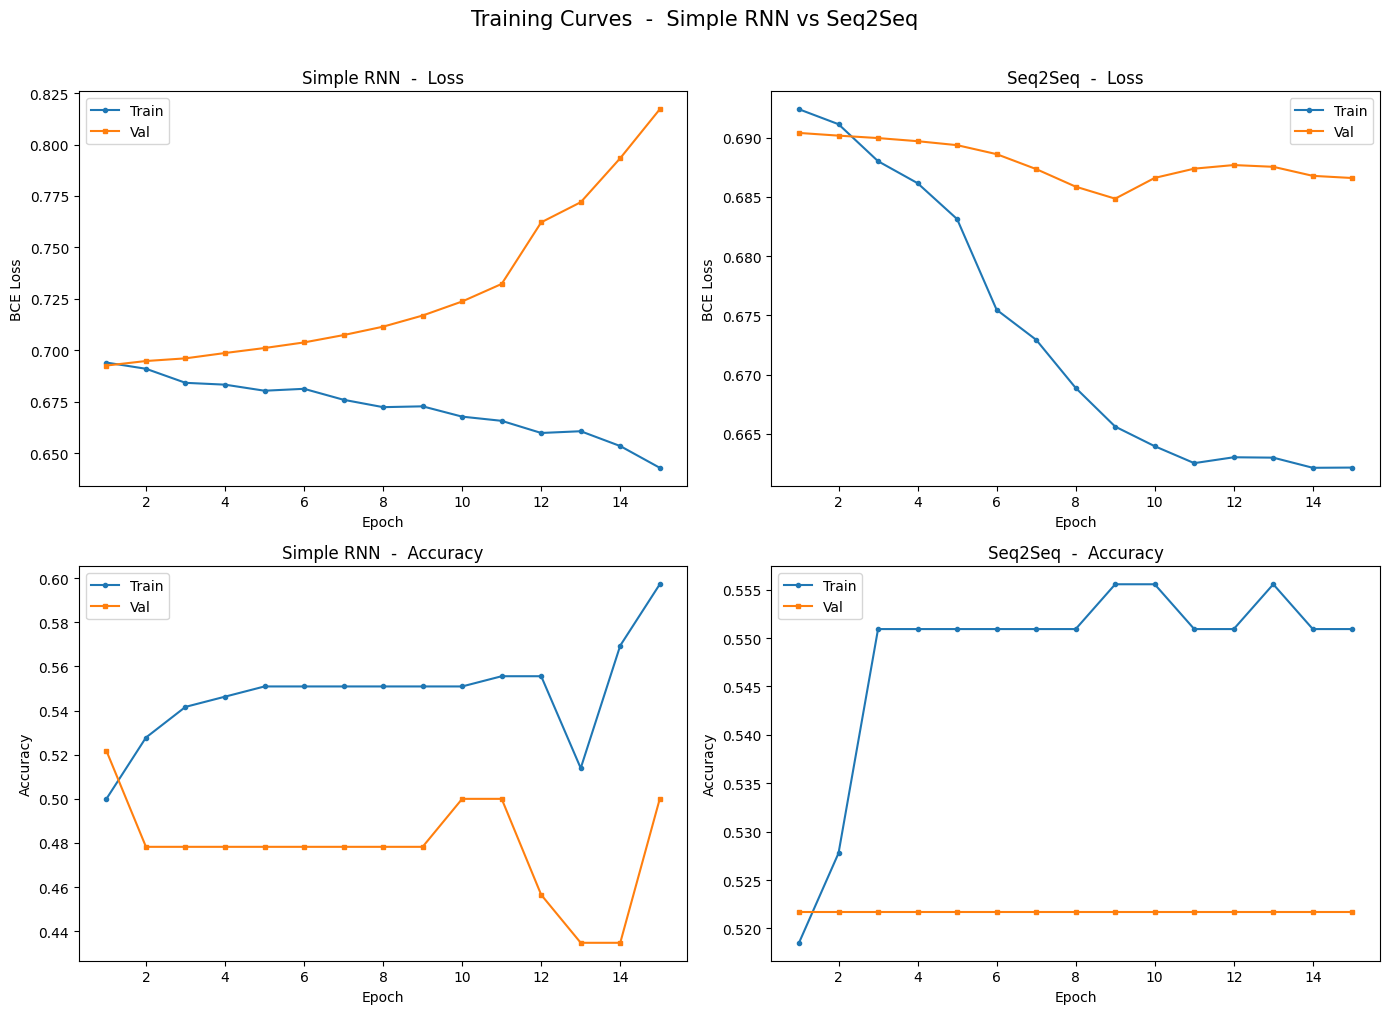

In [23]:
# Training curves  -  loss and accuracy per epoch for both models.
# Diverging train/val curves indicate overfitting; flat val curves indicate
# the model is not learning (class collapse).
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

models_history = [('Simple RNN', rnn_history), ('Seq2Seq', seq2seq_history)]
epochs_range   = range(1, EPOCHS + 1)

for col, (name, history) in enumerate(models_history):
    # Loss curves
    axes[0][col].plot(epochs_range, history['train_loss'], label='Train', marker='o', markersize=3)
    axes[0][col].plot(epochs_range, history['val_loss'],   label='Val',   marker='s', markersize=3)
    axes[0][col].set_title(f'{name}  -  Loss')
    axes[0][col].set_xlabel('Epoch')
    axes[0][col].set_ylabel('BCE Loss')
    axes[0][col].legend()

    # Accuracy curves
    axes[1][col].plot(epochs_range, history['train_acc'], label='Train', marker='o', markersize=3)
    axes[1][col].plot(epochs_range, history['val_acc'],   label='Val',   marker='s', markersize=3)
    axes[1][col].set_title(f'{name}  -  Accuracy')
    axes[1][col].set_xlabel('Epoch')
    axes[1][col].set_ylabel('Accuracy')
    axes[1][col].legend()

plt.suptitle('Training Curves  -  Simple RNN vs Seq2Seq', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('figures/phase5_training_curves.png', dpi=150)
plt.show()


---
## Phase 6: Model Evaluation and Conclusion

We evaluate both models on the **held-out test set** (47 samples, never seen during training or hyperparameter selection) using:
- **Accuracy**, with a majority-class baseline for context
- **Confusion Matrix**, to visualise true/false positive and negative rates
- **Classification Report**, precision, recall, and F1 per class

The **majority-class baseline** always predicts the most frequent class (Negative, 51.06% of the test set). Any model that fails to exceed this threshold has not learned anything useful beyond the class prior.


In [24]:
criterion = nn.BCELoss()

_, rnn_test_acc,    rnn_preds,    rnn_true    = evaluate(rnn_model,    test_loader, criterion, DEVICE)
_, seq2seq_test_acc, seq2seq_preds, seq2seq_true = evaluate(seq2seq_model, test_loader, criterion, DEVICE)

# Majority-class baseline: always predict the most frequent class in the test set
majority_class = int(np.bincount(np.array(rnn_true, dtype=int)).argmax())
majority_acc   = np.mean(np.array(rnn_true) == majority_class)

print(f'Majority-class baseline : {majority_acc:.4f} ({majority_acc*100:.2f}%)')
print(f'Simple RNN   -  Test Acc  : {rnn_test_acc:.4f} ({rnn_test_acc*100:.2f}%)')
print(f'Seq2Seq      -  Test Acc  : {seq2seq_test_acc:.4f} ({seq2seq_test_acc*100:.2f}%)')


Majority-class baseline : 0.5106 (51.06%)
Simple RNN   -  Test Acc  : 0.5106 (51.06%)
Seq2Seq      -  Test Acc  : 0.5106 (51.06%)


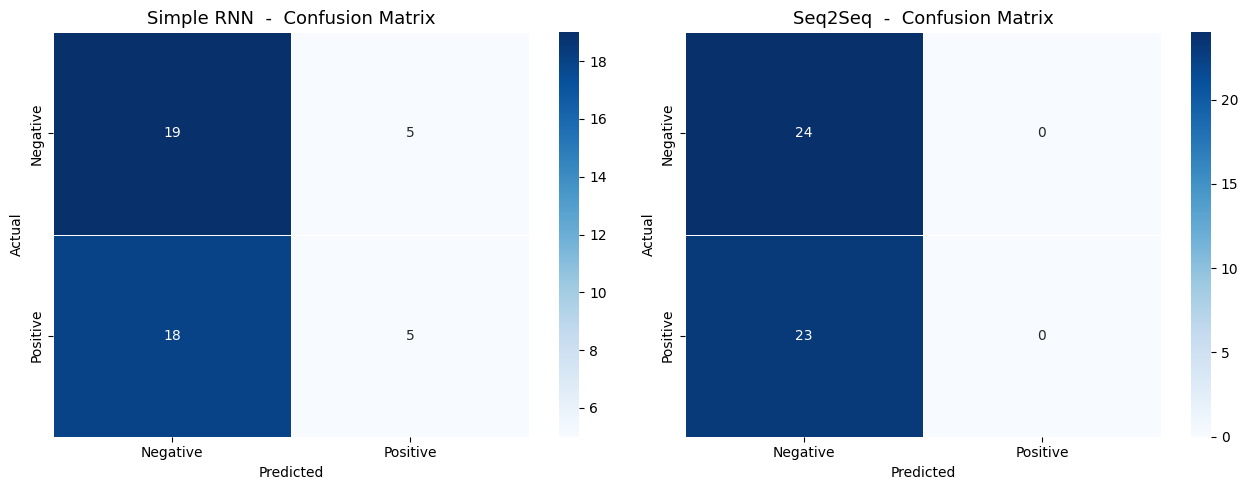

In [25]:
# Confusion matrices  -  rows = actual class, columns = predicted class.
# A model that collapses to the majority class will show an empty right column
# (all Positive samples predicted as Negative).
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, preds, true in [
    (axes[0], 'Simple RNN', rnn_preds,     rnn_true),
    (axes[1], 'Seq2Seq',    seq2seq_preds, seq2seq_true)
]:
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'],
                linewidths=0.5)
    ax.set_title(f'{name}  -  Confusion Matrix', fontsize=13)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('figures/phase6_confusion_matrices.png', dpi=150)
plt.show()


In [26]:
# Classification reports - precision, recall, F1, and support per class.
# zero_division=0 suppresses the UndefinedMetricWarning when a class has
# no predicted samples (i.e. class collapse), setting precision to 0.0.
print('=== Simple RNN  -  Classification Report ===')
print(classification_report(rnn_true, rnn_preds,
                            target_names=['Negative', 'Positive'],
                            zero_division=0))

print('=== Seq2Seq  -  Classification Report ===')
print(classification_report(seq2seq_true, seq2seq_preds,
                            target_names=['Negative', 'Positive'],
                            zero_division=0))


=== Simple RNN  -  Classification Report ===
              precision    recall  f1-score   support

    Negative       0.51      0.79      0.62        24
    Positive       0.50      0.22      0.30        23

    accuracy                           0.51        47
   macro avg       0.51      0.50      0.46        47
weighted avg       0.51      0.51      0.47        47

=== Seq2Seq  -  Classification Report ===
              precision    recall  f1-score   support

    Negative       0.51      1.00      0.68        24
    Positive       0.00      0.00      0.00        23

    accuracy                           0.51        47
   macro avg       0.26      0.50      0.34        47
weighted avg       0.26      0.51      0.35        47



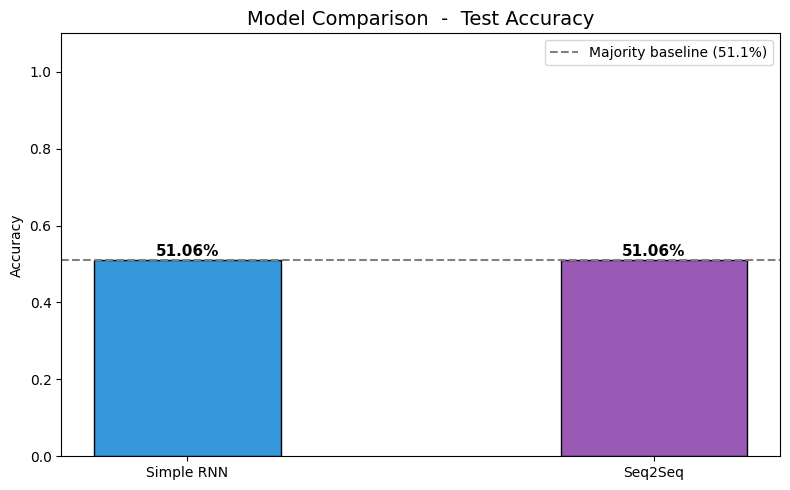

In [27]:
# --- Model Comparison Bar Chart ---
models    = ['Simple RNN', 'Seq2Seq']
test_accs = [rnn_test_acc, seq2seq_test_acc]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(models, test_accs, color=['#3498db', '#9b59b6'],
              edgecolor='black', width=0.4)

# Annotate bars
for bar, acc in zip(bars, test_accs):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{acc*100:.2f}%', ha='center', fontweight='bold', fontsize=11)

# Majority-class baseline reference line
ax.axhline(majority_acc, color='gray', linestyle='--', linewidth=1.5,
           label=f'Majority baseline ({majority_acc*100:.1f}%)')

ax.set_ylim(0, 1.1)
ax.set_title('Model Comparison  -  Test Accuracy', fontsize=14)
ax.set_ylabel('Accuracy')
ax.legend()
plt.tight_layout()
plt.savefig('figures/phase6_model_comparison.png', dpi=150)
plt.show()


### Critical Reflection and Conclusion

---

**Which model performed better and why?**

| Model | Test Accuracy | Notes |
|---|---|---|
| Majority-class baseline | 51.06% | Always predicts Negative (most frequent class) |
| Simple RNN (GRU) | 51.06% | Partial learning: 22% Positive recall, matches baseline overall |
| Seq2Seq | 51.06% | Full collapse: 0% Positive recall, identical to baseline |

All three achieve the same overall accuracy (51.06%), but the classification reports reveal an important difference. The **Simple RNN shows partial learning**: it correctly identifies 22% of Positive comments (recall = 0.22, precision = 0.50), meaning it has learned *some* signal beyond the majority class. The **Seq2Seq fully collapsed**: it predicts every comment as Negative (recall = 0.00 on Positive), making it functionally identical to the majority-class baseline.

Neither model meaningfully outperforms the baseline in overall accuracy. This is not surprising given the constraints:
- Only **~215 training samples** after the 70/15/15 split
- **Noisy pseudo-labels** from an English-only DistilBERT model applied to a multilingual dataset
- **Random weight initialisation** without pre-trained embeddings

The Seq2Seq model's additional parameters (two LSTM layers vs. one GRU) provide no advantage and cause full collapse by overfitting the encoder to noise. The Simple RNN, with fewer parameters, at least learns a weak signal.

---

**Key lessons learned:**

1. **Overall accuracy is misleading on imbalanced predictions.** Both models score 51.06% accuracy, but the classification report exposes the difference: the Simple RNN has non-zero Positive recall while the Seq2Seq does not. F1-score per class is a more informative metric than accuracy alone.

2. **Dataset size is the primary bottleneck.** ~215 training samples is insufficient for training recurrent networks from scratch. Even simple models require at least 1,000-2,000 labelled examples to learn non-trivial patterns. The aggressive cleaning pipeline (38% of comments dropped) critically reduced the usable corpus.

3. **Pseudo-label noise propagates.** DistilBERT was trained on English movie reviews (SST-2). Our dataset contains substantial non-English content (Russian, Korean, Japanese, Spanish). The model's predictions on these comments are unreliable, introducing label noise that makes it harder for the RNN to learn. A multilingual labelling model would significantly improve label quality.

4. **Class collapse is the dominant failure mode on small data.** When the training signal is weak (small N, noisy labels), gradient descent finds the degenerate solution of always predicting the majority class. Mitigation strategies include: class-weighted loss, label smoothing, or collecting more balanced data.

5. **Architecture complexity does not help without data.** The Seq2Seq encoder-decoder adds parameters without adding useful inductive bias for this task. On small datasets, simpler models with stronger regularisation outperform complex ones.

6. **Transfer learning is the right tool for small NLP datasets.** Rather than training RNNs from scratch, fine-tuning a pre-trained model (e.g., DistilBERT itself) on the labelled comments would yield far better results, even with only 300 samples.

---

**Proposed improvements:**

- **Use a multilingual labelling model** (e.g., `xlm-roberta-base` fine-tuned on Twitter sentiment) for Phase 2 to correctly label non-English comments.
- **Expand the dataset** to 1,000-2,000 comments across multiple Olympics-related videos to give the models sufficient training signal.
- **Relax the cleaning filter** to >= 2 words minimum to retain more short but informative comments (e.g., "Great game!").
- **Apply class-weighted BCE loss** to penalise the majority-class collapse: `nn.BCELoss(weight=torch.tensor([pos_weight]))`.
- **Use pre-trained word embeddings** (e.g., GloVe 100d) instead of random initialisation to improve generalisation on small data.
- **Add bidirectional GRU** to the Simple RNN to capture both forward and backward context, particularly useful for negations (e.g., "not great").
- **Add attention** to the Seq2Seq decoder so it can focus on the most sentiment-relevant tokens rather than relying solely on the final hidden state.
- **Fine-tune DistilBERT directly** on the labelled comments as an alternative to training RNNs from scratch: even with 300 samples, fine-tuning a pre-trained transformer typically outperforms a randomly-initialised RNN.
- **Apply K-fold cross-validation** instead of a single train/val/test split to obtain more reliable performance estimates on this small dataset.
